# 03 · Score today's BOING (T4) and see who it shows (T5)

**Steps T4 and T5 of the project plan.** Our first recommender is what BOING does today on its Discover page: **show the biggest groups first**.
We give it the quiz prepared in T3 and count how many hidden groups it finds (T4). Every better recommender (T6, T9) will have to beat this score.
Then we count **who gets shown** (T5, sections 7 to 9): how many of the suggestions go to new and small groups, the unfairness rule R4 must fix.

Run notebooks 01 and 02 first. Only the training files are used to make suggestions; the test file is used only to score them.

## 0 · Settings and data

In [1]:
import sys, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

SEED = 0
K = 5               # every recommender suggests 5 groups
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA = ROOT / 'data' / 'sim_v1'
RESULTS = ROOT / 'results'
FIGS = ROOT / 'figures'
RESULTS.mkdir(exist_ok=True)
FIGS.mkdir(exist_ok=True)

# In Colab, the first time: upload sim_v1.zip and sim_v1_split.zip (made by notebooks 01 and 02)
if 'google.colab' in sys.modules and not (DATA / 'train_memberships.csv').exists():
    from google.colab import files
    for name in files.upload():
        with zipfile.ZipFile(name) as z:
            z.extractall(ROOT / 'data')

train = pd.read_csv(DATA / 'train_memberships.csv')    # what a recommender may see
test = pd.read_csv(DATA / 'test_memberships.csv')      # the hidden answers: only used to score
groups = pd.read_csv(DATA / 'groups.csv', usecols=['group_id', 'name', 'open', 'hidden_by_mods'])   # never 'topic'
print(f'{len(train)} visible memberships, {len(test)} hidden ones, {test.user_id.nunique()} users to test')

6428 visible memberships, 1531 hidden ones, 1406 users to test


## 1 · The recommender: biggest groups first

Like BOING's Discover page today:
1. count each group's members, using **the training data only**;
2. keep the groups anyone can see and join: open, and not hidden by moderators;
3. sort them from biggest to smallest;
4. for each user, suggest the first 5 they are not already in.

In [2]:
size = train.groupby('group_id').size().reindex(groups.group_id, fill_value=0)
on_discover = groups.set_index('group_id').query('open == 1 and hidden_by_mods == 0').index
ranking = size[on_discover].sort_values(ascending=False, kind='stable').index.tolist()   # biggest first; ties: smaller id first
joined = train.groupby('user_id').group_id.apply(set)

def recommend_popular(user_id, k=K):
    # The k biggest groups the user is not in yet
    mine = joined.get(user_id, set())
    return [g for g in ranking if g not in mine][:k]

name = groups.set_index('group_id').name
print('The 10 biggest groups on Discover:')
print(pd.DataFrame({'group': name[ranking[:10]].values, 'members': size[ranking[:10]].values},
                   index=range(1, 11)).to_string())

The 10 biggest groups on Discover:
                          group  members
1   Weightlifting for beginners      295
2              Finals countdown      286
3      Korean conversation club      275
4            Midterms countdown      221
5           Japanese in 90 days      220
6        Algorithms study group      219
7         Spanish for beginners      206
8          Algorithms from zero      200
9         Mastering Probability      188
10           30 days of Cycling      169


## 2 · An example

User 1 again (the example from T3): what they are in, what was hidden, and what today's BOING suggests.

In [3]:
hidden = test.groupby('user_id').group_id.apply(set)
uid = 1
print(f'User {uid} is in:', ', '.join(name[sorted(joined[uid])]))
print('Hidden (the answer):', ', '.join(name[sorted(hidden[uid])]))
print('Suggested by today\'s BOING:')
for i, g in enumerate(recommend_popular(uid), 1):
    print(f'  {i}. {name[g]} ({size[g]} members)', '<- right!' if g in hidden[uid] else '')

User 1 is in: Finals countdown, Journaling streak, Korean conversation club, Midterms countdown
Hidden (the answer): Entrance exams accountability group
Suggested by today's BOING:
  1. Weightlifting for beginners (295 members) 
  2. Japanese in 90 days (220 members) 
  3. Algorithms study group (219 members) 
  4. Spanish for beginners (206 members) 
  5. Algorithms from zero (200 members) 


## 3 · The scores

We compare each user's 5 suggestions with their hidden groups:

- **Hit rate:** did at least one of the 5 suggestions find a hidden group? (yes = 1, no = 0)
- **Precision@5:** the share of the 5 suggestions that were right. 1 right → 1 ÷ 5 = 0.2.
- **Recall@5:** the share of the hidden groups that were found. 1 found out of 2 hidden → 0.5.
- **NDCG@5:** like precision, but a right answer near the top counts more. A right answer in position *i* is worth 1/log₂(*i*+1):
  1 at #1, 0.63 at #2, 0.5 at #3, 0.43 at #4, 0.39 at #5. We divide by the best possible total, so 1 = perfect and 0 = nothing right.

Each score is then averaged over all tested users. The tiny example below is checked by hand: the only hidden group is suggested 3rd.

In [4]:
def scores(suggested, hidden_set):
    hits = [g in hidden_set for g in suggested]
    dcg = sum(1 / np.log2(i + 2) for i, hit in enumerate(hits) if hit)
    ideal = sum(1 / np.log2(i + 2) for i in range(min(len(hidden_set), len(suggested))))
    return {'hit_rate': float(any(hits)),
            'precision@5': sum(hits) / len(suggested),
            'recall@5': sum(hits) / len(hidden_set),
            'ndcg@5': float(dcg / ideal)}

print(scores(['a', 'b', 'c', 'd', 'e'], {'c'}))   # expected: hit 1, precision 0.2, recall 1.0, ndcg 0.5

{'hit_rate': 1.0, 'precision@5': 0.2, 'recall@5': 1.0, 'ndcg@5': 0.5}


## 4 · Score everyone, and random suggestions for comparison

A score means little on its own. So we also score **random suggestions**: 5 groups picked at random among the same groups
(open, not hidden, not already joined). Any recommender worth having must beat random.

In [5]:
rng = np.random.default_rng(SEED)
def recommend_random(user_id, k=K):
    mine = joined.get(user_id, set())
    options = [g for g in on_discover if g not in mine]
    return list(rng.choice(options, size=k, replace=False))

tested_users = sorted(hidden.index)
suggestions = {'Popularity (today)': {u: recommend_popular(u) for u in tested_users},
               'Random (for comparison)': {u: recommend_random(u) for u in tested_users}}
per_user = {m: pd.DataFrame([scores(s[u], hidden[u]) for u in tested_users], index=tested_users)
            for m, s in suggestions.items()}
results = pd.DataFrame({m: df.mean() for m, df in per_user.items()}).T.round(3)
results

,hit_rate,precision@5,recall@5,ndcg@5
Popularity (today),0.220,0.044,0.207,0.131
Random (for comparison),0.049,0.010,0.044,0.026


## 5 · Checks

In [6]:
pop = suggestions['Popularity (today)']
allowed = set(on_discover)
checks = {
    'every tested user gets exactly 5 suggestions': all(len(s) == K for s in pop.values()),
    'no suggestion is a group the user is already in': all(not (set(s) & joined.get(u, set())) for u, s in pop.items()),
    'only open groups not hidden by moderators are suggested': all(set(s) <= allowed for s in pop.values()),
    'suggestions go from biggest to smallest': all(list(size[s]) == sorted(size[s], reverse=True) for s in pop.values()),
    'the scoring gives the hand-checked answer': scores(['a', 'b', 'c', 'd', 'e'], {'c'}) == {'hit_rate': 1.0, 'precision@5': 0.2, 'recall@5': 1.0, 'ndcg@5': 0.5},
    'every score is between 0 and 1': bool(((results >= 0) & (results <= 1)).all().all()),
}
for check, ok in checks.items():
    print('✓' if ok else '✗', check)
assert all(checks.values()), 'Some checks failed (see ✗ above)'

✓ every tested user gets exactly 5 suggestions
✓ no suggestion is a group the user is already in
✓ only open groups not hidden by moderators are suggested
✓ suggestions go from biggest to smallest
✓ the scoring gives the hand-checked answer
✓ every score is between 0 and 1


## 6 · Results

In [7]:
p, r = results.loc['Popularity (today)'], results.loc['Random (for comparison)']
n_distinct = len({g for s in pop.values() for g in s})
print(f"Popularity: P@5 = {p['precision@5']:.3f}, R@5 = {p['recall@5']:.3f}, NDCG@5 = {p['ndcg@5']:.3f}")
print(f"For {p['hit_rate']:.0%} of users at least one of the 5 suggestions was right (random: {r['hit_rate']:.0%}).")
print(f"Across all {len(tested_users)} users, only {n_distinct} different groups were ever suggested.")
results.to_csv(RESULTS / 't4_baseline.csv')

Popularity: P@5 = 0.044, R@5 = 0.207, NDCG@5 = 0.131
For 22% of users at least one of the 5 suggestions was right (random: 5%).
Across all 1406 users, only 10 different groups were ever suggested.


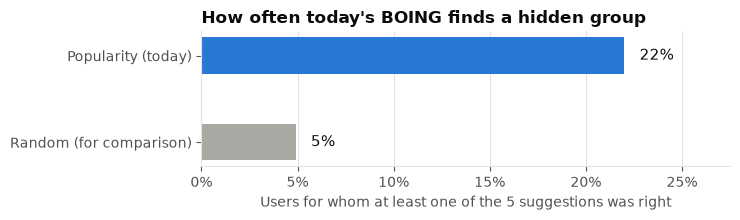

In [8]:
INK, MUTED, GRID, BLUE, GREY = '#0b0b0b', '#52514e', '#e4e3df', '#2a78d6', '#a9a8a2'
labels = ['Random (for comparison)', 'Popularity (today)']
values = [r['hit_rate'] * 100, p['hit_rate'] * 100]
fig, ax = plt.subplots(figsize=(7.5, 2.3))
bars = ax.barh(labels, values, color=[GREY, BLUE], height=0.42)
for bar, v in zip(bars, values):
    ax.text(v + 0.8, bar.get_y() + bar.get_height() / 2, f'{v:.0f}%', va='center', color=INK, fontsize=11)
ax.set_xlim(0, max(values) * 1.25)
ax.xaxis.set_major_formatter(PercentFormatter(100, decimals=0))
ax.set_xlabel('Users for whom at least one of the 5 suggestions was right', color=MUTED)
ax.tick_params(colors=MUTED, labelsize=10)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
for side in ['left', 'bottom']:
    ax.spines[side].set_color(GRID)
ax.xaxis.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.set_title('How often today\'s BOING finds a hidden group', loc='left', color=INK, fontsize=12, fontweight='bold')
fig.tight_layout()
fig.savefig(FIGS / 't4_hit_rate.png', dpi=170, bbox_inches='tight')
plt.show()

## What's next

- **T5, who gets shown** (below): count how often each group appears in the suggestions. Today's ranking shows almost everyone the same few groups,
  so new and small groups never appear.
- **T6, two better recommenders** (notebook 04): "people in X also joined Y" and "similar descriptions". They take the same quiz, and the scores above are the ones to beat.

## 7 · T5: who gets shown

**Step T5 of the project plan.** Each time a group appears in someone's 5 suggestions, it gets *exposure*: a chance to be seen and joined.
We count where the 7,030 slots go (1,406 tested users × 5 suggestions):

- **Newcomer share:** the share of slots that go to **new** groups (created in the last 30 days) or **small** ones (fewer than 10 members in the training data).
  Rule R4 asks for at least *q* of them (we will try 20% and 40%).
- **Gini of exposure:** one number for how unequally the slots are shared among the 129 groups on Discover, counting those never shown.
  0 = every group is shown equally often; close to 1 = one group gets every slot.
- **Coverage:** how many different groups are ever shown. **Largest share:** the share of all slots taken by the most-shown group
  (R4's cap *c*: we will try 5% and 10%).

From here on, the notebooks share their code in one file, `boingrec.py` (in this folder). First we check that it gives exactly the T4 scores above.
It also does one thing T4 did not: it never suggests a group the user marked "not interested" (rule R7).

In [9]:
# Colab only: also upload boingrec.py (from the notebooks folder). Locally this does nothing.
if 'google.colab' in sys.modules and not Path('boingrec.py').exists():
    from google.colab import files
    files.upload()
import boingrec as br

vis = br.load_visible()    # what a recommender may read
ans = br.load_answers()    # the answer key (hidden memberships, hidden topics): only for scoring
t5_lists = {'popularity': br.top_k(br.popularity_scores(vis, tested_users), vis),
            'random': br.random_lists(vis, tested_users)}
t5 = pd.DataFrame({br.label(m): br.evaluate(lists, ans.test, vis, ans.group_topic) for m, lists in t5_lists.items()}).T

same_scores = (t5.loc['Popularity (today)', br.RELEVANCE].round(3) == results.loc['Popularity (today)', br.RELEVANCE]).all()
n_changed = sum(t5_lists['popularity'][u] != pop[u] for u in tested_users)
print('Popularity scored with boingrec:', t5.loc['Popularity (today)', br.RELEVANCE].round(3).to_dict())
print(f'Same scores as T4: {same_scores}. Skipping "not interested" groups changes {n_changed} of the '
      f'{len(tested_users)} lists, but none of the scores.')
assert same_scores, 'boingrec does not reproduce T4: find out why before going on'

Popularity scored with boingrec: {'hit_rate': 0.22, 'precision@5': 0.044, 'recall@5': 0.207, 'ndcg@5': 0.131}
Same scores as T4: True. Skipping "not interested" groups changes 3 of the 1406 lists, but none of the scores.


### Where the slots go

In [10]:
disc = br.discover_groups(vis.groups)          # the 129 groups on Discover
n_members = br.group_sizes(vis)                # members in the training data
newcomers = br.newcomer_groups(vis) & set(disc)
created = vis.groups.set_index('group_id').created_day
shown = pd.DataFrame({br.label(m): br.exposure(lists, disc) for m, lists in t5_lists.items()})
slots = K * len(tested_users)

t5_table = t5[['users', 'newcomer_share', 'gini', 'coverage', 'largest_share']].assign(
    slots=slots, discover_groups=len(disc), new_or_small_groups=len(newcomers)).astype({'users': int, 'coverage': int})
br.save_table(t5_table, 't5_exposure.csv')
per_group = pd.DataFrame({'name': name[disc], 'members': n_members[disc], 'created_day': created[disc],
                          'new_or_small': [int(g in newcomers) for g in disc]}).join(shown)
per_group.sort_values('members', ascending=False, kind='stable').to_csv(RESULTS / 't5_exposure_per_group.csv')

p5, r5 = t5_table.loc['Popularity (today)'], t5_table.loc['Random (floor)']
print(f'{len(disc)} groups on Discover, {len(newcomers)} of them new or small; {slots:,} slots in all.')
for label_, row in [('Popularity', p5), ('Random', r5)]:
    print(f'{label_:10}: newcomer share {row.newcomer_share:5.1%} | Gini {row.gini:.3f} | {row.coverage:3.0f} groups ever shown | '
          f'the most-shown group takes {row.largest_share:.1%} of all slots')
most = shown['Popularity (today)'].sort_values(ascending=False, kind='stable').head(10)
print('\nThe only groups popularity ever shows:')
print(pd.DataFrame({'members': n_members[most.index].values, 'times shown': most.values,
                    'share of slots': (most / slots).map('{:.1%}'.format).values},
                   index=name[most.index].values).to_string())

129 groups on Discover, 53 of them new or small; 7,030 slots in all.
Popularity: newcomer share  0.0% | Gini 0.953 |  10 groups ever shown | the most-shown group takes 17.4% of all slots
Random    : newcomer share 41.7% | Gini 0.079 | 129 groups ever shown | the most-shown group takes 1.0% of all slots

The only groups popularity ever shows:
                             members  times shown share of slots
Japanese in 90 days              220         1225          17.4%
Midterms countdown               221         1217          17.3%
Korean conversation club         275         1183          16.8%
Finals countdown                 286         1175          16.7%
Weightlifting for beginners      295         1155          16.4%
Algorithms study group           219          688           9.8%
Spanish for beginners            206          265           3.8%
Algorithms from zero             200          100           1.4%
Mastering Probability            188           20           0.3%
30 day

## 8 · The picture

Left: every group on Discover, from the biggest to the smallest, and how many of the 7,030 slots it gets. Right: the same counts as a
**Lorenz curve**: groups are lined up from the least shown to the most shown, and the curve adds up their slots. If every group got the same
number of slots, the curve would follow the diagonal. The further it sags below, the more unequal; the Gini is the size of that gap.

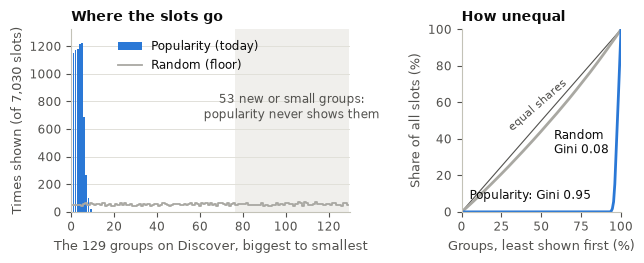

In [11]:
by_size = n_members[disc].sort_values(ascending=False, kind='stable').index      # biggest first; ties: smaller id first
x = np.arange(1, len(by_size) + 1)
is_newcomer = np.array([g in newcomers for g in by_size])
counts_pop, counts_rnd = shown['Popularity (today)'][by_size], shown['Random (floor)'][by_size]

br.use_style()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(br.WIDTH, 2.7), gridspec_kw=dict(width_ratios=[1.75, 1]))
start = x[is_newcomer].min() - 0.5
a1.axvspan(start, x[-1] + 0.5, color='#f0efec', linewidth=0, zorder=0)
bars = a1.bar(x, counts_pop, width=0.85, color=br.colour('popularity'), label=br.label('popularity'), zorder=2)
line, = a1.step(x, counts_rnd, where='mid', color=br.colour('random'), linewidth=1.3, label=br.label('random'), zorder=3)
a1.text((start + x[-1]) / 2, counts_pop.max() * 0.62,
        f'{is_newcomer.sum()} new or small groups:\npopularity never shows them', ha='center', va='center', fontsize=8.5, color=br.MUTED)
a1.set_xlim(0, x[-1] + 1)
a1.set_ylim(0, counts_pop.max() * 1.08)
a1.set_xlabel(f'The {len(disc)} groups on Discover, biggest to smallest')
a1.set_ylabel(f'Times shown (of {slots:,} slots)')
a1.yaxis.grid(True)
a1.legend(handles=[bars, line], loc='upper center', bbox_to_anchor=(0.42, 1.0))
a1.set_title('Where the slots go')

a2.plot([0, 100], [0, 100], color=br.MUTED, linewidth=0.8)
a2.text(50, 56, 'equal shares', rotation=37, ha='center', va='bottom', fontsize=8, color=br.MUTED,
        rotation_mode='anchor', transform_rotates_text=True)
for m in ['random', 'popularity']:
    fx, fy = br.lorenz_curve(shown[br.label(m)])
    a2.plot(fx * 100, fy * 100, color=br.colour(m), linewidth=2)
gini_txt = {m: t5_table.loc[br.label(m), 'gini'] for m in ['random', 'popularity']}
a2.text(58, 38, f'Random\nGini {gini_txt["random"]:.2f}', ha='left', va='center', fontsize=8.5)
a2.text(5, 9, f'Popularity: Gini {gini_txt["popularity"]:.2f}', ha='left', va='center', fontsize=8.5)
a2.set_xlim(0, 100)
a2.set_ylim(0, 100)
a2.set_xlabel('Groups, least shown first (%)')
a2.set_ylabel('Share of all slots (%)')
a2.set_title('How unequal')
fig.tight_layout(w_pad=2.5)
br.save_fig(fig, 't5_exposure.png')
plt.show()

## 9 · Checks (T5)

In [12]:
t4_random = {u: [int(g) for g in s] for u, s in suggestions['Random (for comparison)'].items()}
checks = {
    'boingrec rebuilds T4\'s popularity lists exactly when the "not interested" filter is off':
        br.top_k(br.popularity_scores(vis, tested_users), vis, not_interested=False) == pop,
    'boingrec rebuilds T4\'s random lists exactly when the "not interested" filter is off':
        br.random_lists(vis, tested_users, not_interested=False) == t4_random,
    'every slot is counted once: 5 per tested user': (shown.sum() == slots).all(),
    'no suggestion is a group the user marked "not interested"':
        not set(zip(vis.not_interested.user_id, vis.not_interested.group_id)) & {(u, g) for u, s in t5_lists['popularity'].items() for g in s},
    'Gini by hand: equal shares give 0': br.gini([3, 3, 3, 3]) == 0,
    'Gini by hand: one of 4 groups gets every slot gives 3/4': abs(br.gini([0, 0, 0, 8]) - 0.75) < 1e-12,
    'new or small: created in the last 30 days or fewer than 10 members':
        newcomers == {g for g in disc if created[g] > br.TODAY - br.NEW_DAYS or n_members[g] < br.SMALL},
    'newcomer share, Gini and largest share are between 0 and 1':
        bool(t5_table[['newcomer_share', 'gini', 'largest_share']].stack().between(0, 1).all()),
    'a recommender never gets a hidden column':
        not {'interests', 'is_fake'} & set(vis.users.columns) and 'topic' not in vis.groups.columns,
}
for check, ok in checks.items():
    print('✓' if ok else '✗', check)
assert all(checks.values()), 'Some checks failed (see ✗ above)'

✓ boingrec rebuilds T4's popularity lists exactly when the "not interested" filter is off
✓ boingrec rebuilds T4's random lists exactly when the "not interested" filter is off
✓ every slot is counted once: 5 per tested user
✓ no suggestion is a group the user marked "not interested"
✓ Gini by hand: equal shares give 0
✓ Gini by hand: one of 4 groups gets every slot gives 3/4
✓ new or small: created in the last 30 days or fewer than 10 members
✓ newcomer share, Gini and largest share are between 0 and 1
✓ a recommender never gets a hidden column


## What we learned

- **T4:** today's BOING (biggest groups first) finds a hidden group for **22%** of users, against 5% for random suggestions:
  P@5 = 0.044, R@5 = 0.207, NDCG@5 = 0.131.
- **T5:** it shows almost everyone the same few groups. Only **10 of the 129** groups on Discover are ever suggested, the **53 new or small groups
  get 0%** of the 7,030 slots (random suggestions would give them 42%), and the Gini of exposure is **0.953** (random: 0.079).
  Five groups take about 17% of all slots each (the largest, *Japanese in 90 days*, **17.4%**): together, 85% of all slots.
- So ranking by size is both unfair to newcomers and not very relevant. This is the "rich get richer" problem that rule R4 must fix, measured.
- Files: `results/t4_baseline.csv`, `results/t5_exposure.csv`, `results/t5_exposure_per_group.csv`, `figures/t4_hit_rate.png`, `figures/t5_exposure.png`.

**Next:** notebook 04 builds two better recommenders (T6) and the first comparison table (T7).